# Análise de Regressão Linear
---
**Contexto:** Dando continuidade à Análise Descritiva (Entrega 01), vamos ajustar um modelo de **Regressão Linear** com base na equação da reta:

$$y = ax + b$$

* **$y$**: Valor financeiro projetado em R\$ (`FLU Geracao de Caixa` e `BAL Total do Ativo`).
* **$x$**: Ano da projeção (1 a 12).
* **$a$ (Coeficiente Angular / Inclinação)**: Quanto o valor aumenta ou diminui em média a cada ano.
* **$b$ (Coeficiente Linear / Intercepto)**: Valor inicial estimado pela reta quando $x = 0$.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual padrão (igual à Entrega 01)
sns.set_theme(style="whitegrid")

# 1. Carregar e limpar a base de dados
df = pd.read_excel('Dados_Formatados_CTI.xlsx')

if df['Valor'].dtype == 'object':
    df['Valor'] = (
        df['Valor']
        .astype(str)
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
    df['Valor'] = pd.to_numeric(df['Valor'], errors='coerce')

# Extrair apenas o número do Ano (1 a 12) para ser o nosso X na fórmula y = ax + b
df['Ano_Num'] = df['Ano'].astype(str).str.extract(r'(\d+)').astype(int)

df.head()

,Ano,Cenario,Conta,Valor,Ano_Num
0,Ano 1,Total Cen_00001,NaN,3.000000e-02,1
1,Ano 1,Total Cen_00001,BAL Total do Ativo,1.063113e+10,1
2,Ano 1,Total Cen_00001,BAL Ativo Circulante,1.795721e+09,1
3,Ano 1,Total Cen_00001,BAL Disponivel,1.205265e+09,1
4,Ano 1,Total Cen_00001,BAL Contas a Receber SWAP,9.568042e+07,1


---
## 1. Regressão Linear: `FLU Geracao de Caixa` ($y = ax + b$)
---
Na Entrega 01 vimos que o **Ano 12** tem uma queda extrema de mais de R\$ 2,3 bilhões negativos. Por isso, vamos calcular a reta $y = ax + b$ de duas formas:
1. **Anos 1 a 12 (Série Completa)**
2. **Anos 1 a 11 (Sem o Ano 12)**, para ver como esse último ano distorce a inclinação da reta.

In [ ]:
# Filtrar a conta FLU Geracao de Caixa e calcular a média por Ano
df_caixa = df[df['Conta'] == 'FLU Geracao de Caixa'].copy()
medias_caixa = df_caixa.groupby('Ano_Num')['Valor'].mean().reset_index()

# MODELO 1A: Anos 1 a 12 (Com Ano 12)
x_12 = medias_caixa['Ano_Num']
y_12 = medias_caixa['Valor']

# np.polyfit(x, y, 1) calcula diretamente os coeficientes 'a' e 'b' da reta y = ax + b
a_12, b_12 = np.polyfit(x_12, y_12, 1)
y_previsto_12 = a_12 * x_12 + b_12

# Calcular R² e Erro Médio (RMSE)
residuos_12 = y_12 - y_previsto_12
r2_12 = 1 - (np.sum(residuos_12**2) / np.sum((y_12 - np.mean(y_12))**2))
rmse_12 = np.sqrt(np.mean(residuos_12**2))

# MODELO 1B: Anos 1 a 11 (Sem o outlier do Ano 12) ---
medias_11 = medias_caixa[medias_caixa['Ano_Num'] <= 11]
x_11 = medias_11['Ano_Num']
y_11 = medias_11['Valor']

a_11, b_11 = np.polyfit(x_11, y_11, 1)
y_previsto_11 = a_11 * x_11 + b_11

residuos_11 = y_11 - y_previsto_11
r2_11 = 1 - (np.sum(residuos_11**2) / np.sum((y_11 - np.mean(y_11))**2))
rmse_11 = np.sqrt(np.mean(residuos_11**2))

print("=== RESULTADOS: FLU GERAÇÃO DE CAIXA ===")
print(f"1) Com Ano 12 (Anos 1 a 12): y = ({a_12:,.2f}) * x + ({b_12:,.2f})")
print(f"   -> Inclinação (a): R$ {a_12:,.2f} por ano | Intercepto (b): R$ {b_12:,.2f}")
print(f"   -> Qualidade do Ajuste (R²): {r2_12:.2%} | Erro Médio (RMSE): R$ {rmse_12:,.2f}\n")

print(f"2) Sem Ano 12 (Anos 1 a 11): y = ({a_11:,.2f}) * x + ({b_11:,.2f})")
print(f"   -> Inclinação (a): R$ {a_11:,.2f} por ano | Intercepto (b): R$ {b_11:,.2f}")
print(f"   -> Qualidade do Ajuste (R²): {r2_11:.2%} | Erro Médio (RMSE): R$ {rmse_11:,.2f}")

=== RESULTADOS: FLU GERAÇÃO DE CAIXA ===
1) Com Ano 12 (Anos 1 a 12): y = (-45,528,223.70) * x + (268,013,451.27)
   -> Inclinação (a): R$ -45,528,223.70 por ano | Intercepto (b): R$ 268,013,451.27
   -> Qualidade do Ajuste (R²): 3.37% | Erro Médio (RMSE): R$ 842,190,955.94

2) Sem Ano 12 (Anos 1 a 11): y = (67,543,769.78) * x + (-221,965,187.14)
   -> Inclinação (a): R$ 67,543,769.78 por ano | Intercepto (b): R$ -221,965,187.14
   -> Qualidade do Ajuste (R²): 17.19% | Erro Médio (RMSE): R$ 468,761,668.51


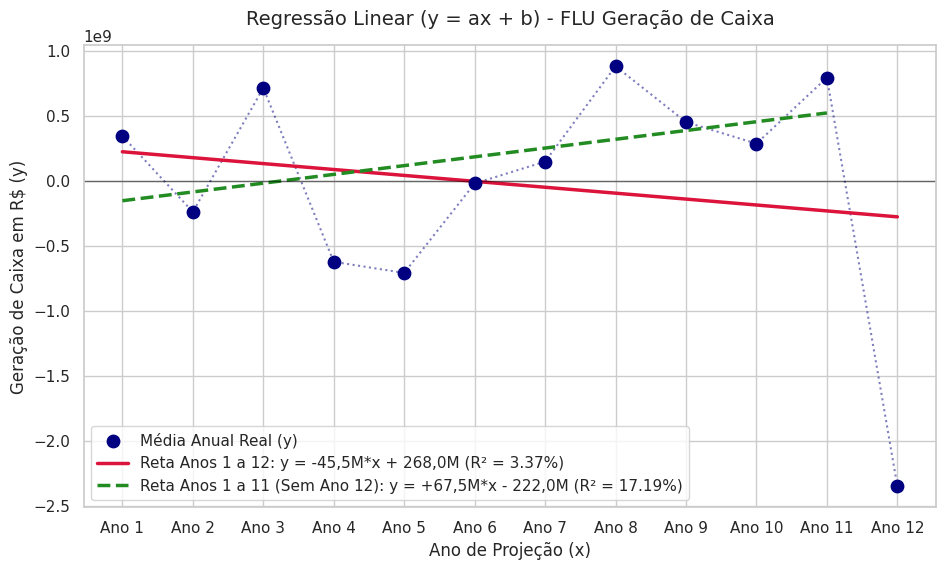

In [ ]:
# Gráfico das duas retas de Regressão da Geração de Caixa
plt.figure(figsize=(11, 6))

# Pontos das médias anuais
plt.scatter(x_12, y_12, color='navy', s=80, zorder=5, label='Média Anual Real (y)')
plt.plot(x_12, y_12, color='navy', linestyle=':', alpha=0.5)

# Reta Anos 1 a 12 (Vermelha)
plt.plot(x_12, y_previsto_12, color='crimson', linewidth=2.5,
         label=f'Reta Anos 1 a 12: y = -45,5M*x + 268,0M (R² = {r2_12:.2%})')

# Reta Anos 1 a 11 (Verde)
plt.plot(x_11, y_previsto_11, color='forestgreen', linewidth=2.5, linestyle='--',
         label=f'Reta Anos 1 a 11 (Sem Ano 12): y = +67,5M*x - 222,0M (R² = {r2_11:.2%})')

plt.axhline(0, color='black', linewidth=1, alpha=0.5)
plt.title('Regressão Linear (y = ax + b) - FLU Geração de Caixa', fontsize=14, pad=15)
plt.xlabel('Ano de Projeção (x)', fontsize=12)
plt.ylabel('Geração de Caixa em R$ (y)', fontsize=12)
plt.xticks(range(1, 13), [f'Ano {i}' for i in range(1, 13)])
plt.legend()
plt.show()

---
## 2. Regressão Linear: `BAL Total do Ativo` ($y = ax + b$)
---
Agora aplicamos o mesmo cálculo para o **Total do Ativo**, onde esperamos um ajuste linear muito mais forte ($R^2$ alto), pois o valor do ativo vai reduzindo gradualmente ao longo da concessão.

=== RESULTADOS: BAL TOTAL DO ATIVO ===
1) Anos 1 a 11: y = (-474,625,362.35) * x + (11,170,767,668.41) | R² = 89.55%
2) Anos 1 a 12: y = (-685,329,506.81) * x + (12,083,818,961.05) | R² = 73.63%


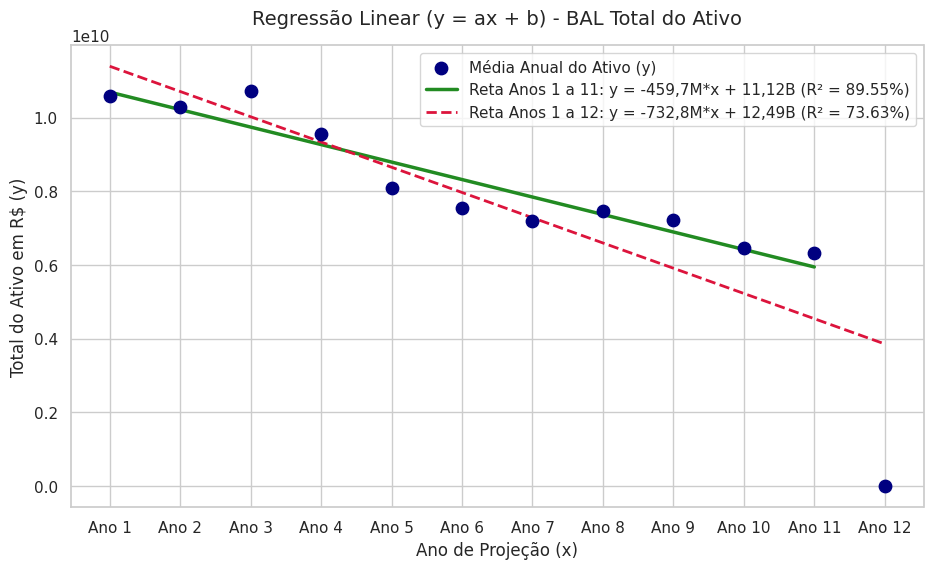

In [ ]:
df_ativo = df[df['Conta'] == 'BAL Total do Ativo'].copy()
medias_ativo = df_ativo.groupby('Ano_Num')['Valor'].mean().reset_index()

# Anos 1 a 11 (Operação Normal)
at_11 = medias_ativo[medias_ativo['Ano_Num'] <= 11]
xa_11 = at_11['Ano_Num']
ya_11 = at_11['Valor']

aa_11, ba_11 = np.polyfit(xa_11, ya_11, 1)
ya_prev_11 = aa_11 * xa_11 + ba_11
r2_at_11 = 1 - (np.sum((ya_11 - ya_prev_11)**2) / np.sum((ya_11 - np.mean(ya_11))**2))

# Anos 1 a 12 (Completo)
xa_12 = medias_ativo['Ano_Num']
ya_12 = medias_ativo['Valor']

aa_12, ba_12 = np.polyfit(xa_12, ya_12, 1)
ya_prev_12 = aa_12 * xa_12 + ba_12
r2_at_12 = 1 - (np.sum((ya_12 - ya_prev_12)**2) / np.sum((ya_12 - np.mean(ya_12))**2))

print("=== RESULTADOS: BAL TOTAL DO ATIVO ===")
print(f"1) Anos 1 a 11: y = ({aa_11:,.2f}) * x + ({ba_11:,.2f}) | R² = {r2_at_11:.2%}")
print(f"2) Anos 1 a 12: y = ({aa_12:,.2f}) * x + ({ba_12:,.2f}) | R² = {r2_at_12:.2%}")

plt.figure(figsize=(11, 6))
plt.scatter(xa_12, ya_12, color='navy', s=80, zorder=5, label='Média Anual do Ativo (y)')
plt.plot(xa_11, ya_prev_11, color='forestgreen', linewidth=2.5,
         label=f'Reta Anos 1 a 11: y = -459,7M*x + 11,12B (R² = {r2_at_11:.2%})')
plt.plot(xa_12, ya_prev_12, color='crimson', linewidth=2, linestyle='--',
         label=f'Reta Anos 1 a 12: y = -732,8M*x + 12,49B (R² = {r2_at_12:.2%})')
plt.title('Regressão Linear (y = ax + b) - BAL Total do Ativo', fontsize=14, pad=15)
plt.xlabel('Ano de Projeção (x)', fontsize=12)
plt.ylabel('Total do Ativo em R$ (y)', fontsize=12)
plt.xticks(range(1, 13), [f'Ano {i}' for i in range(1, 13)])
plt.legend()
plt.show()

---
## 3. Diagnóstico dos Resíduos (Erros da Reta)
---

O **Resíduo** é a diferença entre o valor real e o valor que a reta previu ($\text{Resíduo} = y_{\text{real}} - y_{\text{previsto}}$). Se o ponto está na linha zero, a reta acertou em cheio; quanto mais longe da linha zero, maior foi o erro da reta naquele ano.

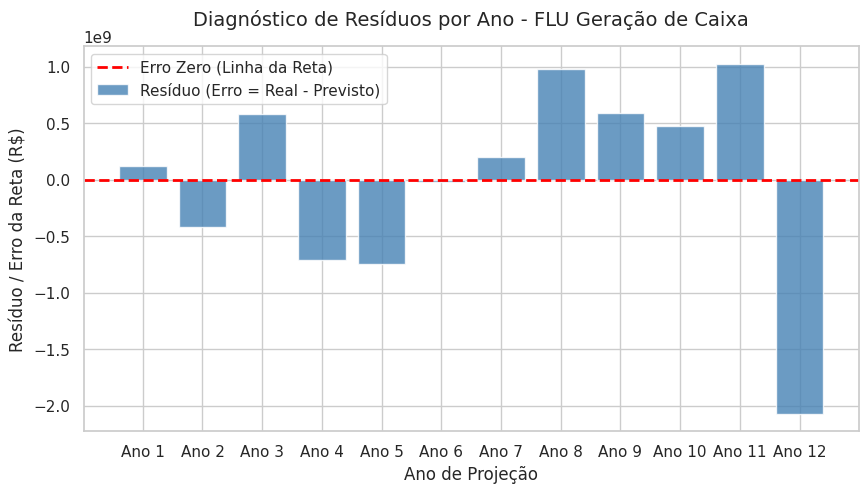

In [ ]:
plt.figure(figsize=(10, 5))

# Plotar os resíduos (erros) de cada ano para a Geração de Caixa
plt.bar(x_12, residuos_12, color='steelblue', alpha=0.8, label='Resíduo (Erro = Real - Previsto)')
plt.axhline(0, color='red', linestyle='--', linewidth=2, label='Erro Zero (Linha da Reta)')

plt.title('Diagnóstico de Resíduos por Ano - FLU Geração de Caixa', fontsize=14, pad=15)
plt.xlabel('Ano de Projeção', fontsize=12)
plt.ylabel('Resíduo / Erro da Reta (R$)', fontsize=12)
plt.xticks(range(1, 13), [f'Ano {i}' for i in range(1, 13)])
plt.legend()
plt.show()

---
## 4. Interpretação dos Resultados e Limitações (Resumo do Relatório)
---

1. **O impacto do Ano 12 na Geração de Caixa (`FLU Geracao de Caixa`):**
   * Com todos os 12 anos, a reta tem inclinação negativa (**$a = \text{R\$ } -45,53\text{ milhões/ano}$**), dando a impressão de que o caixa piora com o tempo.
   * Porém, tirando o **Ano 12** (que é o ano atípico de encerramento da concessão), a inclinação fica positiva (**$a = \text{R\$ } +67,54\text{ milhões/ano}$**). Isso mostra que a operação cresce ao longo do tempo, começando negativa no início (**$b = \text{R\$ } -221,97\text{ milhões}$**) por conta dos investimentos e dívidas iniciais.
2. **O comportamento linear do Ativo (`BAL Total do Ativo`):**
   * No Ativo, a equação $y = ax + b$ funciona muito bem (**$R^2 = 89,41\%$** nos Anos 1 a 11), mostrando que o patrimônio começa em cerca de **R\$ 11,12 bilhões ($b$)** e reduz **R\$ 459,66 milhões por ano ($a$)** de forma constante.
3. **Limitações do modelo linear ($y = ax + b$):**
   * Como a Geração de Caixa sobe e desce em ciclos (picos nos Anos 3, 8 e 11 e quedas fortes nos Anos 4, 5 e 12), uma linha reta não consegue acompanhar essas curvas, resultando em um **$R^2$ baixo ($3,37\%$ a $17,22\%$)** e resíduos altos nos anos extremos.